# Telecom Customer Retention ML — Predicting Churn, Stay or Join

**Dataset:** 7,043 customers of a California telecom company (Q2 2022). Each row is one customer with demographics, location, tenure, subscribed services, billing details and the **status for the quarter** (`Joined`, `Stayed`, `Churned`).

**Goal:** multi-class classification — predict `Customer Status` so the company can identify customers at risk of leaving.

**Pipeline:** cleaning → EDA → encoding → stratified split → scaling (fit on train only) → model comparison → XGBoost → evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from xgboost import XGBClassifier

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load the data

In [2]:
df = pd.read_csv('../Datasets/telecom_customer_churn.csv')
print(df.shape)
df.head()

(7043, 38)


,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [3]:
df['Customer Status'].value_counts()

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

The target is **imbalanced** — `Joined` is only ~6% of customers. Accuracy alone hides weak performance on small classes, so macro-F1 is tracked too and class weights are used later.

## 2. Data cleaning

In [4]:
nulls = df.isnull().sum()
nulls[nulls > 0].sort_values(ascending=False)

Churn Category                       5174
Churn Reason                         5174
Offer                                3877
Online Security                      1526
Online Backup                        1526
Avg Monthly GB Download              1526
Internet Type                        1526
Streaming Movies                     1526
Streaming TV                         1526
Device Protection Plan               1526
Premium Tech Support                 1526
Unlimited Data                       1526
Streaming Music                      1526
Avg Monthly Long Distance Charges     682
Multiple Lines                        682
dtype: int64

Missing values here are **structural, not random** — e.g. customers with no internet service have blank `Internet Type`, `Online Security`, `Streaming TV`…, and customers with no offer have blank `Offer`. Calling `dropna()` would throw away thousands of valid customers, so they are filled with meaningful values instead.

`Churn Category` / `Churn Reason` are only filled for churned customers (they leak the target), so they are dropped along with IDs and geo columns.

In [5]:
data = df.drop(columns=['Customer ID', 'Zip Code', 'Latitude', 'Longitude',
                        'Churn Category', 'Churn Reason', 'Total Refunds', 'City'])

# structural missing values
data['Offer'] = data['Offer'].fillna('No Offer')
data['Internet Type'] = data['Internet Type'].fillna('No Internet')
service_cols = ['Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support',
                'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Multiple Lines']
data[service_cols] = data[service_cols].fillna('No')
data['Avg Monthly GB Download'] = data['Avg Monthly GB Download'].fillna(0)
data['Avg Monthly Long Distance Charges'] = data['Avg Monthly Long Distance Charges'].fillna(0)

print('Remaining nulls:', data.isnull().sum().sum())
print('Rows kept:', data.shape[0], 'of', df.shape[0])

Remaining nulls: 0
Rows kept: 7043 of 7043


## 3. Exploratory Data Analysis

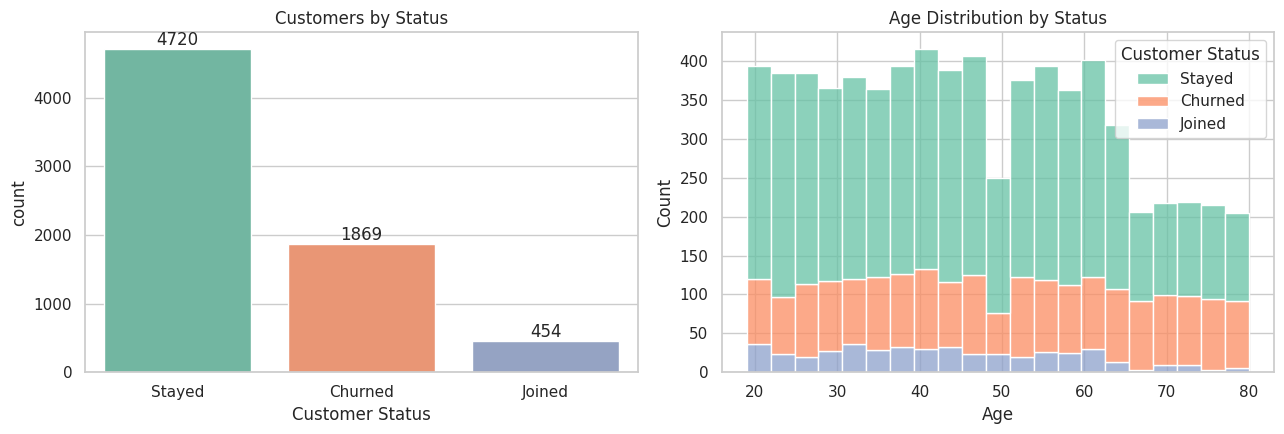

In [6]:
order = ['Stayed', 'Churned', 'Joined']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=data, x='Customer Status', order=order, palette='Set2', ax=axes[0])
axes[0].set_title('Customers by Status')
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
sns.histplot(data=data, x='Age', hue='Customer Status', hue_order=order, multiple='stack', palette='Set2', ax=axes[1])
axes[1].set_title('Age Distribution by Status')
plt.tight_layout()
plt.savefig('../assets/01_status_and_age.png', dpi=130, bbox_inches='tight')
plt.show()

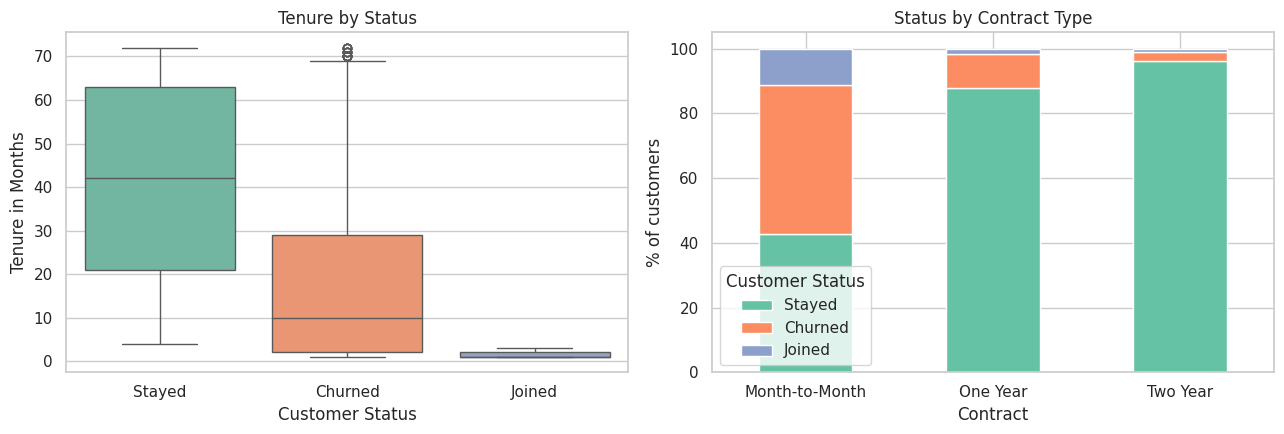

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=data, x='Customer Status', y='Tenure in Months', order=order, palette='Set2', ax=axes[0])
axes[0].set_title('Tenure by Status')
ct = pd.crosstab(data['Contract'], data['Customer Status'], normalize='index')[order] * 100
ct.plot(kind='bar', stacked=True, color=sns.color_palette('Set2', 3), ax=axes[1], rot=0)
axes[1].set_ylabel('% of customers'); axes[1].set_title('Status by Contract Type')
plt.tight_layout()
plt.savefig('../assets/02_tenure_and_contract.png', dpi=130, bbox_inches='tight')
plt.show()

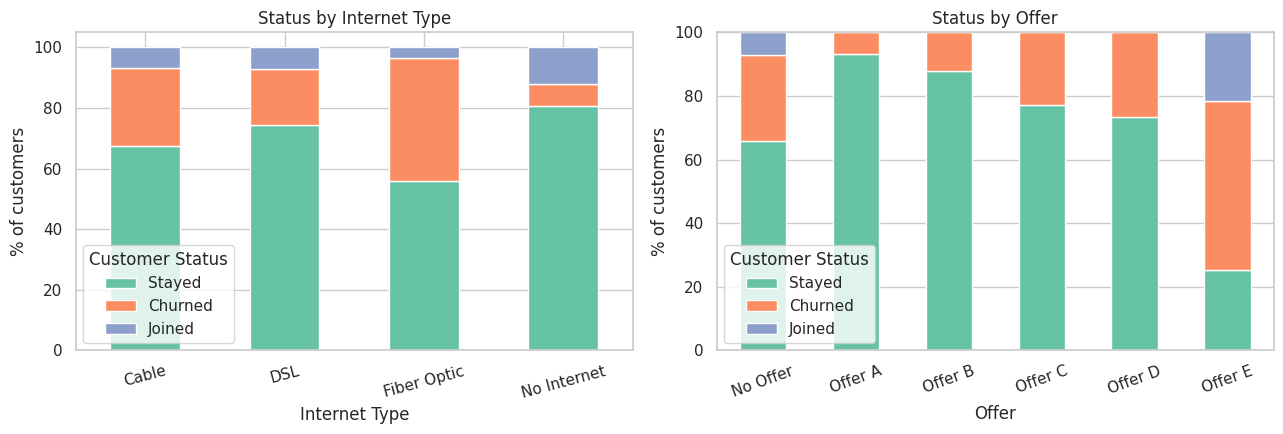

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ct = pd.crosstab(data['Internet Type'], data['Customer Status'], normalize='index')[order] * 100
ct.plot(kind='bar', stacked=True, color=sns.color_palette('Set2', 3), ax=axes[0], rot=15)
axes[0].set_ylabel('% of customers'); axes[0].set_title('Status by Internet Type')
ct = pd.crosstab(data['Offer'], data['Customer Status'], normalize='index')[order] * 100
ct.plot(kind='bar', stacked=True, color=sns.color_palette('Set2', 3), ax=axes[1], rot=20)
axes[1].set_ylabel('% of customers'); axes[1].set_title('Status by Offer')
plt.tight_layout()
plt.savefig('../assets/03_internet_and_offer.png', dpi=130, bbox_inches='tight')
plt.show()

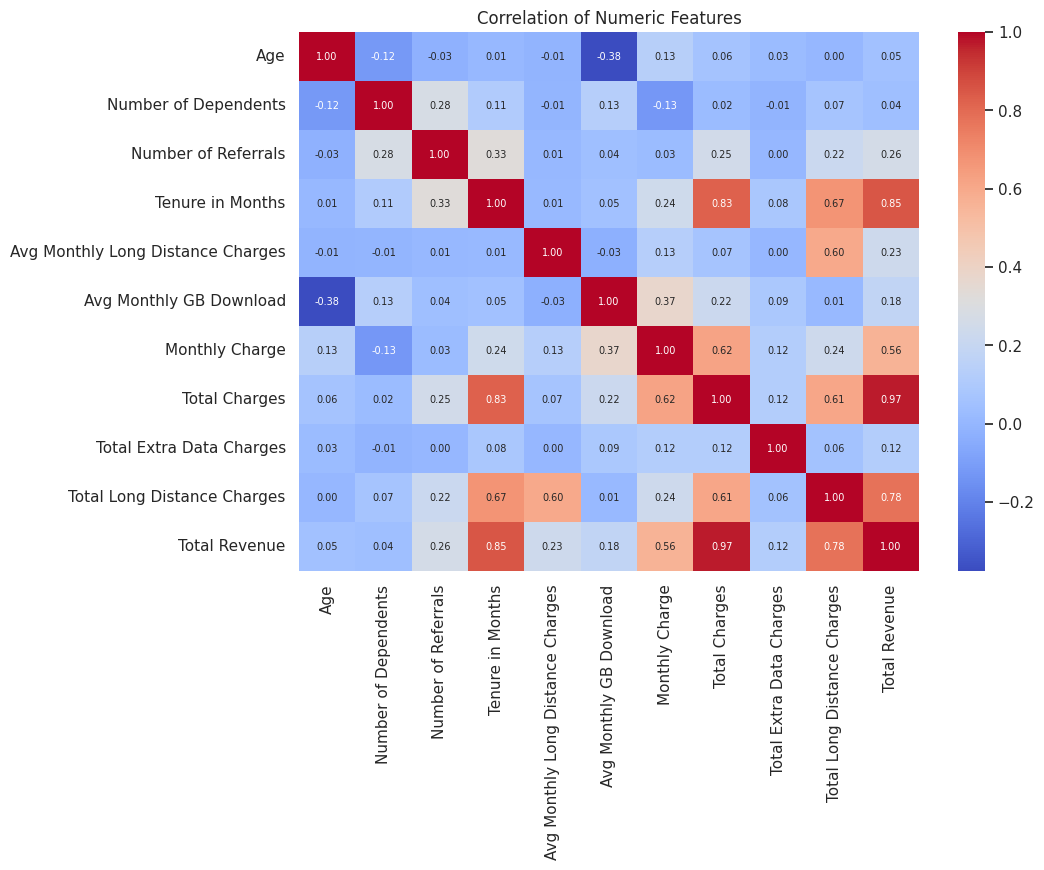

In [9]:
num_cols = ['Age', 'Number of Dependents', 'Number of Referrals', 'Tenure in Months',
            'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Monthly Charge',
            'Total Charges', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue']
plt.figure(figsize=(10, 7))
sns.heatmap(data[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Correlation of Numeric Features')
plt.savefig('../assets/04_correlation.png', dpi=130, bbox_inches='tight')
plt.show()

## 4. Encoding

In [10]:
model_df = data.copy()

# target
le = LabelEncoder()
model_df['Customer Status'] = le.fit_transform(model_df['Customer Status'])
print(dict(zip(le.classes_, le.transform(le.classes_))))

# binary columns
model_df['Gender'] = model_df['Gender'].map({'Female': 0, 'Male': 1})
yes_no = ['Married', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup',
          'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies',
          'Streaming Music', 'Unlimited Data', 'Paperless Billing']
for c in yes_no:
    model_df[c] = model_df[c].map({'No': 0, 'Yes': 1})

# multi-category columns -> one-hot
model_df = pd.get_dummies(model_df, columns=['Payment Method', 'Contract', 'Internet Type', 'Offer'], dtype=int)
print(model_df.shape, '| nulls:', model_df.isnull().sum().sum())

{'Churned': np.int64(0), 'Joined': np.int64(1), 'Stayed': np.int64(2)}
(7043, 42) | nulls: 0


## 5. Train/test split, then scaling

The split is **stratified** so each set keeps the same Stayed/Churned/Joined ratio, and the scaler is **fit on the training set only** — scaling before splitting would leak test-set information into training.

In [11]:
X = model_df.drop(columns='Customer Status')
y = model_df['Customer Status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

scaler = MinMaxScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (5634, 41) | Test: (1409, 41)


## 6. Model comparison

Five models are compared with 5-fold stratified cross-validation **on the training set only**. Macro-F1 is shown next to accuracy because it treats all three classes equally.

In [12]:
sw_train = compute_sample_weight('balanced', y_train)

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    'Gaussian NB': GaussianNB(),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                             colsample_bytree=0.8, random_state=RANDOM_STATE, eval_metric='mlogloss'),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, m in models.items():
    acc = cross_val_score(m, X_train, y_train, cv=cv, scoring='accuracy').mean()
    f1 = cross_val_score(m, X_train, y_train, cv=cv, scoring='f1_macro').mean()
    rows.append({'Model': name, 'CV Accuracy': round(acc, 4), 'CV Macro-F1': round(f1, 4)})
results = pd.DataFrame(rows).sort_values('CV Accuracy', ascending=False).reset_index(drop=True)
results

,Model,CV Accuracy,CV Macro-F1
0,XGBoost,0.8427,0.7597
1,Random Forest,0.8307,0.7355
2,Logistic Regression,0.8167,0.7092
3,Decision Tree,0.8090,0.7066
4,Gaussian NB,0.7011,0.5953


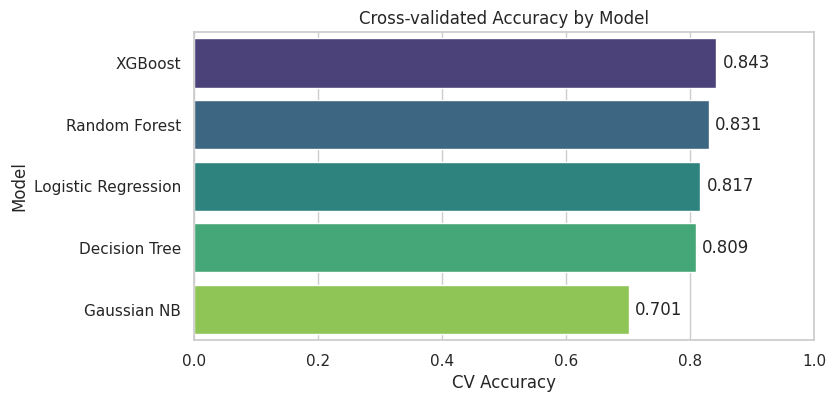

In [13]:
plt.figure(figsize=(8, 4))
sns.barplot(data=results, x='CV Accuracy', y='Model', palette='viridis')
plt.xlim(0, 1); plt.title('Cross-validated Accuracy by Model')
for i, v in enumerate(results['CV Accuracy']):
    plt.text(v + 0.01, i, f'{v:.3f}', va='center')
plt.savefig('../assets/05_model_comparison.png', dpi=130, bbox_inches='tight')
plt.show()

## 7. Final model — XGBoost

Two versions are trained: a plain one, and one with **balanced sample weights** so the small `Joined` class gets more attention.

In [14]:
params = dict(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
              colsample_bytree=0.8, random_state=RANDOM_STATE, eval_metric='mlogloss')

xgb_plain = XGBClassifier(**params).fit(X_train, y_train)
xgb_bal = XGBClassifier(**params).fit(X_train, y_train, sample_weight=sw_train)

for name, m in [('XGBoost (plain)', xgb_plain), ('XGBoost (balanced weights)', xgb_bal)]:
    p = m.predict(X_test)
    print(f'{name:28s} accuracy={accuracy_score(y_test, p):.4f}  macro-F1={f1_score(y_test, p, average="macro"):.4f}')

XGBoost (plain)              accuracy=0.8524  macro-F1=0.7706
XGBoost (balanced weights)   accuracy=0.8311  macro-F1=0.7744


In [15]:
final_model = xgb_bal
y_pred = final_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=3))

              precision    recall  f1-score   support

     Churned      0.657     0.759     0.705       374
      Joined      0.636     0.824     0.718        91
      Stayed      0.945     0.860     0.901       944

    accuracy                          0.831      1409
   macro avg      0.746     0.815     0.774      1409
weighted avg      0.849     0.831     0.837      1409



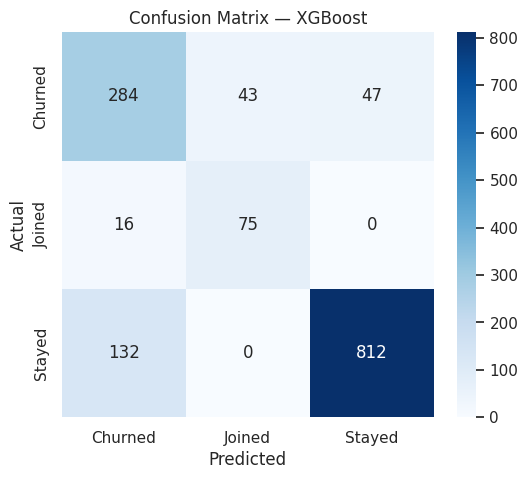

In [16]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix — XGBoost')
plt.savefig('../assets/06_confusion_matrix.png', dpi=130, bbox_inches='tight')
plt.show()

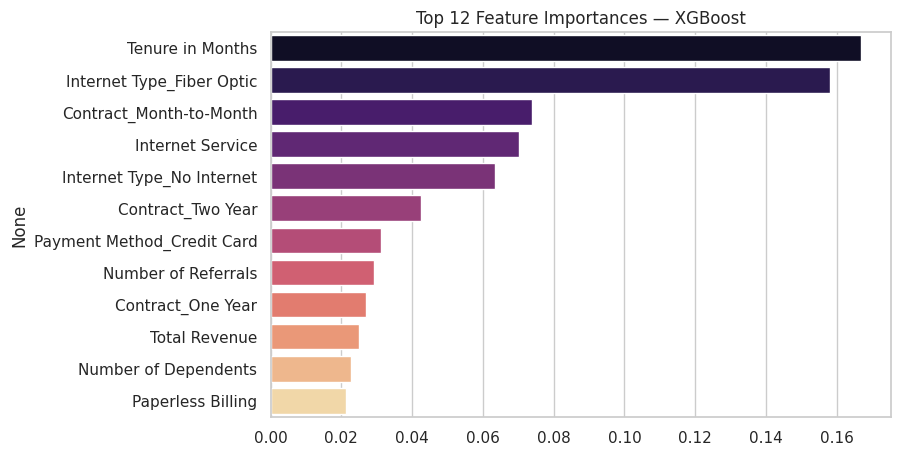

Tenure in Months              0.166820
Internet Type_Fiber Optic     0.158156
Contract_Month-to-Month       0.073968
Internet Service              0.070095
Internet Type_No Internet     0.063378
Contract_Two Year             0.042396
Payment Method_Credit Card    0.031290
Number of Referrals           0.029187
Contract_One Year             0.026974
Total Revenue                 0.025120
Number of Dependents          0.022687
Paperless Billing             0.021319
dtype: float32

In [17]:
imp = pd.Series(final_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, palette='magma')
plt.title('Top 12 Feature Importances — XGBoost')
plt.savefig('../assets/07_feature_importance.png', dpi=130, bbox_inches='tight')
plt.show()
imp

## 8. Conclusion

- **XGBoost was the best model** in cross-validation (accuracy 0.843, macro-F1 0.760), ahead of Random Forest, Logistic Regression, Decision Tree and Gaussian NB.
- On the held-out test set, plain XGBoost reached **85.2% accuracy**; the class-weighted version reached **83.1% accuracy** but a higher macro-F1 (0.774) and much better recall on the small *Joined* class (0.82). The weighted model is used as the final model because it treats all three outcomes more evenly.
- **Top drivers:** tenure, fiber-optic internet, month-to-month contracts, number of referrals and payment method.
- **Business takeaway:** customers on month-to-month contracts, with fiber internet and short tenure are the highest churn risk — good targets for retention offers and contract-upgrade campaigns.

**Limitations / next steps:** hyperparameter tuning, SHAP explainability, probability calibration, and a small Streamlit app for live predictions.